# Optical depth through a simulation box: the minimal recipe

Three skewers through the TNG50-4 box, their optical depth τ and flux F in H I Lyα and Si III 1206.5 Å, in four steps:
1. the ingredients;
2. one call for τ;
3. one call for the fields at the skewer points;
4. a plot.

The explanations are in `3_fields_from_simulations.ipynb` and `6_optical_depth_from_simulations.ipynb`.

In [1]:
import os, sys
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)   # quiet GPU-plugin messages
import numpy as np, jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
from skewerjax.config.setup_matplotlib import matplotlib_tol_config, ENTITY_COLORS as EC, MODE_STYLES as MS, add_panel_letters
font, rc = matplotlib_tol_config(); plt.rc("font", **font); plt.rcParams.update(rc)
from skewerjax.simulations import snapshot_readers, simulation_skewers
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology
from skewerjax.constants.lines import LineBundle
from skewerjax.constants.physical_constants import phys

## 1. The ingredients

- **The simulation:** the snapshot path and number.
- **The cosmology:** the simulation's own.
- **The lines.**
- **A `SkewerBundle` of 3 skewers:** straight paths across the box along x, sampled every 0.25 km/s of Hubble flow. The observer is before the first point, so a(x) is defined from there (`ICs_defined_at_index=0`).

In [2]:
simulation = snapshot_readers.ArepoHDF5Reader("/home/STORAGE/TNG50-4", 25)
H = simulation.header
cosmology = Cosmology(H0=100 * H.h * 1e6 * phys.Gyr_to_s / phys.Gpc_to_m, Omega_r_0=0.0, Omega_m_0=H.omega_m, Omega_k_0=0.0, Omega_lambda_0=H.omega_l)
line_bundle = LineBundle(["HI-LyA", "SiIII-1206"], ref_line_id="HI-LyA")

L, N_ppsk = H.box_cMpc, int(round(H.vmax_kms / 0.25)) + 1                 # box [cMpc]; points every 0.25 km/s
x = np.linspace(0.0, L, N_ppsk)
points = np.stack([np.stack([x, np.full_like(x, y), np.full_like(x, z)], -1) for y, z in [(10.0, 30.0), (25.0, 5.0), (40.0, 45.0)]])
skewer_bundle = SkewerBundle(spatial_points=jnp.asarray(points), a0=H.a, ICs_defined_at_index=0,
                             ICs_at_emission_or_absorption="absorption", cosmologies=cosmology)

## 2. The optical depth and the fields

`SimulationSkewers.from_bundle` finds the gas cells along the skewers. `optical_depth` returns τ of every line, on a periodic velocity grid over one box length. `fields` returns the same `Fields` structure as the toy models, sampled at the skewer points.

In [3]:
skewers = simulation_skewers.SimulationSkewers.from_bundle(simulation, skewer_bundle)
velocities, tau = skewers.optical_depth(line_bundle)                    # tau: (N_lines, N_skewers, N_v)
flux = np.exp(-tau)
fields = skewers.fields(line_bundle.species_keys)
sampled = fields.sample(skewer_bundle.quadri_vectors[0], skewer_bundle.los_directions)
print(f"{len(skewers.cells):,} cells along the 3 skewers | tau {tau.shape} | <F>: Lya {flux[0].mean():.3f}, Si III {flux[1].mean():.4f}")

14,623 cells along the 3 skewers | tau (2, 3, 3973) | <F>: Lya 0.506, Si III 0.9996


## 3. Along each skewer: n, T, τ and F

The fields are plotted against the velocity of each point in the spectrum, c ln(a_†/a(x)), so that the gas lines up with the absorption it causes. The peculiar velocities shift the absorption by tens of km/s. Lyα is blue and solid, Si III red and dashed; the physical densities are n_com / a³.

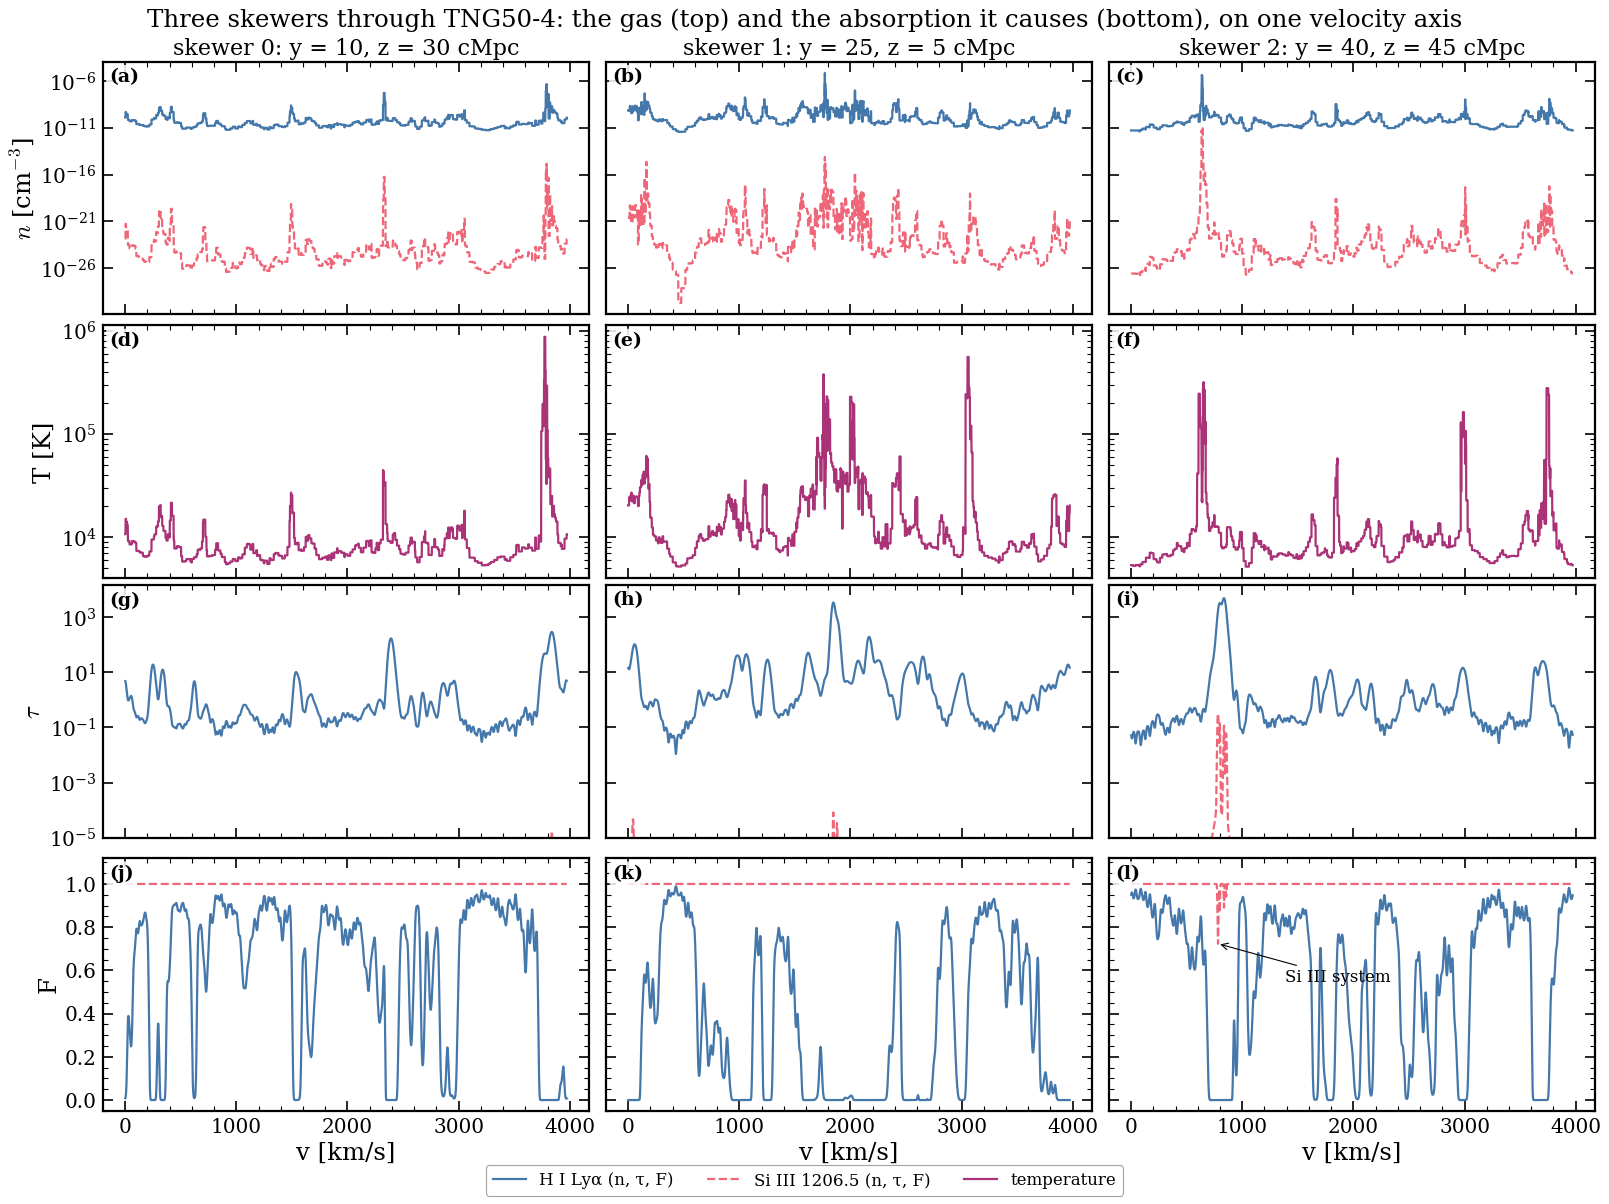

In [4]:
a = np.asarray(skewer_bundle.quadri_vectors[0][..., 0])
v_points = phys.c_kms * np.log(a[:, :1] / a)                             # where each point's gas absorbs (without v_pec)
fig, axs = plt.subplots(4, 3, figsize=(20, 15), sharex=True, sharey="row", layout="constrained")
styles = (MS["default"], MS["matched"])                                    # Lya solid, Si III dashed (and blue / red)
for k in range(3):
    for j, line in enumerate(line_bundle.lines):
        sp, c = line.species, EC[line.species]
        axs[0, k].semilogy(v_points[k], np.asarray(sampled[sp]["number_density"])[k] / H.a ** 3, color=c, **styles[j], label=f"$n$({sp})")
        axs[2, k].semilogy(velocities, np.maximum(tau[j, k], 1e-6), color=c, **styles[j], label=line.id)
        axs[3, k].plot(velocities, flux[j, k], color=c, **styles[j], label=line.id)
    axs[1, k].semilogy(v_points[k], np.asarray(sampled["HI"]["temperature"])[k], color=EC["temperature"], lw=2)
    axs[0, k].set_title(f"skewer {k}: y = {points[k, 0, 1]:.0f}, z = {points[k, 0, 2]:.0f} cMpc", fontsize=20)
    axs[3, k].set_xlabel("v [km/s]")
axs[0, 0].set_ylabel(r"$n$ [cm$^{-3}$]"); axs[1, 0].set_ylabel("T [K]"); axs[2, 0].set_ylabel(r"$\tau$"); axs[3, 0].set_ylabel("F")
axs[2, 0].set_ylim(1e-5, None); axs[3, 0].set_ylim(-0.05, 1.12)
fig.legend(handles=axs[3, 0].get_lines()[:2] + axs[1, 0].get_lines()[:1], labels=["H I Lyα (n, τ, F)", "Si III 1206.5 (n, τ, F)", "temperature"],
           loc="outside lower center", ncols=3)
jsi = int(np.argmax(tau[1, 2])); axs[3, 2].annotate("Si III system", xy=(velocities[jsi], flux[1, 2, jsi]), xytext=(velocities[jsi] + 600, 0.55),
                                                 fontsize=15, arrowprops=dict(arrowstyle="->"))
fig.suptitle("Three skewers through TNG50-4: the gas (top) and the absorption it causes (bottom), on one velocity axis", fontsize=22)
add_panel_letters(axs, size=17)
plt.show()

That is all: a snapshot, a cosmology, a `LineBundle` and a `SkewerBundle`, then `from_bundle(...).optical_depth(...)`. A last cell checks that the outputs make sense.

In [5]:
assert np.all(np.isfinite(tau)) and np.all(tau >= 0) and np.all((flux >= 0) & (flux <= 1))
assert set(sampled) == {"HI", "SiIII"} and np.all(np.asarray(sampled["HI"]["temperature"]) > 0)
print("checks passed: tau finite and >= 0, 0 <= F <= 1, fields for H I and Si III")

checks passed: tau finite and >= 0, 0 <= F <= 1, fields for H I and Si III
